# Import Required Modules

In [1]:
!pip install -q cartopy

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import xarray as xr
from google.colab import drive
import math

In [3]:
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:          # in Colab: !pip install cartopy
    HAS_CARTOPY = False
    print('cartopy not installed — drawing without coastlines (pip install cartopy)')

# Mount Drive

In [5]:
drive.mount('/content/drive')

Mounted at /content/drive


# Define Plot Saving Path

In [6]:
FIG_DIR = Path('/content/drive/MyDrive/MSc-research-code/EDA')
FIG_DIR.mkdir(exist_ok=True)

# Define Required Constants

In [7]:
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
})

LAYER_FEATURES = ['sst', 'temp_0_50m', 'temp_50_100m', 'temp_100_150m']
LAYER_NAMES = ['SST', '0–50 m', '50–100 m', '100–150 m']

ALL_FEATURES = ["u10", "v10", "t2m", "msl",'wind_speed','ssr_flux', 'str_flux', 'sensible_flux', 'latent_flux', 'net_heat_flux','sst','ohc_0_50m','temp_0_50m','ohc_50_100m','temp_50_100m','ohc_100_150m','temp_100_150m']
SST_FEATURES = ['sst']
Layer01_FEATURES= ['ohc_0_50m','temp_0_50m']
Layer02_FEATURES= ['ohc_50_100m','temp_50_100m']
Layer03_FEATURES= ['ohc_100_150m','temp_100_150m']

TARGETS = ['mhw_sst', 'mhw_layer1', 'mhw_layer2', 'mhw_layer3']
TARGET_NAMES = ['SST MHW', '0–50 m MHW', '50–100 m MHW', '100–150 m MHW']

LEAD_TIMES = [3, 5, 7, 9, 12, 14]


# Define Required Functions

In [8]:
def savefig(name, tight=True):
    """Save figure to figures folder."""
    if tight:
        plt.tight_layout()
    path = FIG_DIR / f'{name}.png'
    plt.savefig(path, dpi=150, bbox_inches='tight',
                facecolor='white')
    print(f'  Saved --> {path}')
    plt.show()
    plt.close()

print(f'Figures will be saved to: {FIG_DIR.absolute()}')

Figures will be saved to: /content/drive/MyDrive/MSc-research-code/EDA


##Convert 3D Data to 2D

In [9]:

def xr_to_df(ds, features, targets):
    """Convert xarray Dataset to pandas DataFrame."""
    print('Converting xarray → pandas...')
    stacked = ds[features + targets].stack(sample=('time', 'latitude', 'longitude'))
    df = stacked.to_dataframe().reset_index()

    initial_len = len(df)
    df = df.dropna(subset=['sst'])
    print(f'  Removed {initial_len - len(df):,} land points')

    df = df.sort_values(['latitude', 'longitude', 'time']).reset_index(drop=True)
    df['location'] = df['latitude'].astype(str) + '_' + df['longitude'].astype(str)

    for col in features:
        if col in df.columns:
            df[col] = df[col].astype(np.float32)
    for col in targets:
        if col in df.columns:
            df[col] = df[col].astype(np.int8)

    print(f'  Samples: {len(df):,}')
    return df


# Load Datast from Drive

In [10]:
# Load dataset
NETCDF_FILE = '/content/drive/MyDrive/MSc-research-code/data/ocean_atmos_DAILY_WITH_LABELS_1993_2025.nc'

print('Loading NetCDF...')
ds = xr.open_dataset(NETCDF_FILE)
df = xr_to_df(ds, ALL_FEATURES, TARGETS)
ds.close()

print(f'Data loaded: {df.shape}')
print('='*80)


Loading NetCDF...
Converting xarray → pandas...
  Removed 3,061,462 land points
  Samples: 11,703,463
Data loaded: (11703463, 27)


# Dataset Overview

In [11]:
# Dataset overview
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('Date range:', df['time'].min(), 'to', df['time'].max())
print('Unique grid cells:', df['location'].nunique())
print('Latitude range:', df['latitude'].min(), 'to', df['latitude'].max())
print('Longitude range:', df['longitude'].min(), 'to', df['longitude'].max())

# Summary statistics for all features
df[ALL_FEATURES].describe()

Rows: 11703463
Columns: 27
Date range: 1993-01-01 00:00:00 to 2025-12-31 00:00:00
Unique grid cells: 971
Latitude range: 31.0 to 37.0
Longitude range: 24.0 to 36.0


,u10,v10,t2m,msl,wind_speed,ssr_flux,str_flux,sensible_flux,latent_flux,net_heat_flux,sst,ohc_0_50m,temp_0_50m,ohc_50_100m,temp_50_100m,ohc_100_150m,temp_100_150m
count,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.170346e+07,1.099234e+07,1.099234e+07,1.066690e+07,1.066690e+07,1.044995e+07,1.044995e+07
mean,2.388836e+00,-1.451477e+00,2.024501e+01,1.013666e+05,5.086425e+00,2.115347e+02,-8.902700e+01,-1.352145e+01,-1.082418e+02,7.444458e-01,2.166274e+01,4.075941e+09,2.057223e+01,3.599545e+09,1.770484e+01,3.213181e+09,1.660140e+01
std,3.506361e+00,3.519670e+00,4.690263e+00,1.472789e+04,2.646392e+00,7.974480e+01,1.436874e+01,2.190469e+01,7.218288e+01,1.423969e+02,4.033426e+00,6.982326e+08,3.363462e+00,4.427246e+08,1.692356e+00,2.532728e+08,1.023670e+00
min,-1.756723e+01,-1.878806e+01,-2.492737e+00,9.851123e+04,1.862393e-03,1.195312e+00,-1.869422e+02,-5.319596e+02,-9.986765e+02,-1.497268e+03,1.224136e+01,3.734463e+08,1.338979e+01,3.789971e+08,1.345966e+01,4.568518e+08,1.346809e+01
25%,2.540207e-01,-3.629814e+00,1.627139e+01,1.009701e+05,3.116423e+00,1.362891e+02,-9.791175e+01,-1.805194e+01,-1.377204e+02,-8.243975e+01,1.781680e+01,3.529152e+09,1.771206e+01,3.416443e+09,1.671279e+01,3.105207e+09,1.598461e+01
50%,2.606232e+00,-1.546600e+00,2.004794e+01,1.013374e+05,4.773712e+00,2.209102e+02,-8.917209e+01,-7.353577e+00,-9.040082e+01,2.087970e+01,2.133170e+01,4.028849e+09,2.023475e+01,3.576940e+09,1.748859e+01,3.235868e+09,1.663354e+01
75%,4.739248e+00,6.800041e-01,2.460721e+01,1.017303e+05,6.703336e+00,2.879336e+02,-8.015332e+01,-2.000854e+00,-5.820392e+01,1.150233e+02,2.535294e+01,4.614978e+09,2.313609e+01,3.778248e+09,1.848634e+01,3.346372e+09,1.719682e+01
max,1.704678e+01,1.688879e+01,3.731351e+01,1.036913e+05,1.883709e+01,3.432188e+02,-1.212203e+01,1.384802e+02,4.572021e+00,2.452708e+02,3.327042e+01,6.293024e+09,3.203670e+01,5.540978e+09,2.879486e+01,4.599418e+09,2.360405e+01


# Class Counts of All Depth Layers

In [ ]:
def plot_class_counts_all_layers(df):
    rows = []
    for target, name in zip(TARGETS, TARGET_NAMES):
        counts = df[target].value_counts(dropna=False).sort_index()
        for cls, count in counts.items():
            rows.append({'Layer': name, 'Class': int(cls) if pd.notna(cls) else 'NaN', 'Count': count})
    out = pd.DataFrame(rows)

    plt.figure(figsize=(9, 4.5))
    sns.barplot(data=out, x='Layer', y='Count', hue='Class')
    plt.title('Class Counts for MHW Targets Across Depth Layers')
    plt.xlabel('Target layer')
    plt.ylabel('Number of samples')
    plt.xticks(rotation=20)
    plt.legend(title='Class')
    savefig('class_counts_all_layers')
    return out


  Saved --> /content/drive/MyDrive/MSc-research-code/EDA/class_counts_all_layers.png


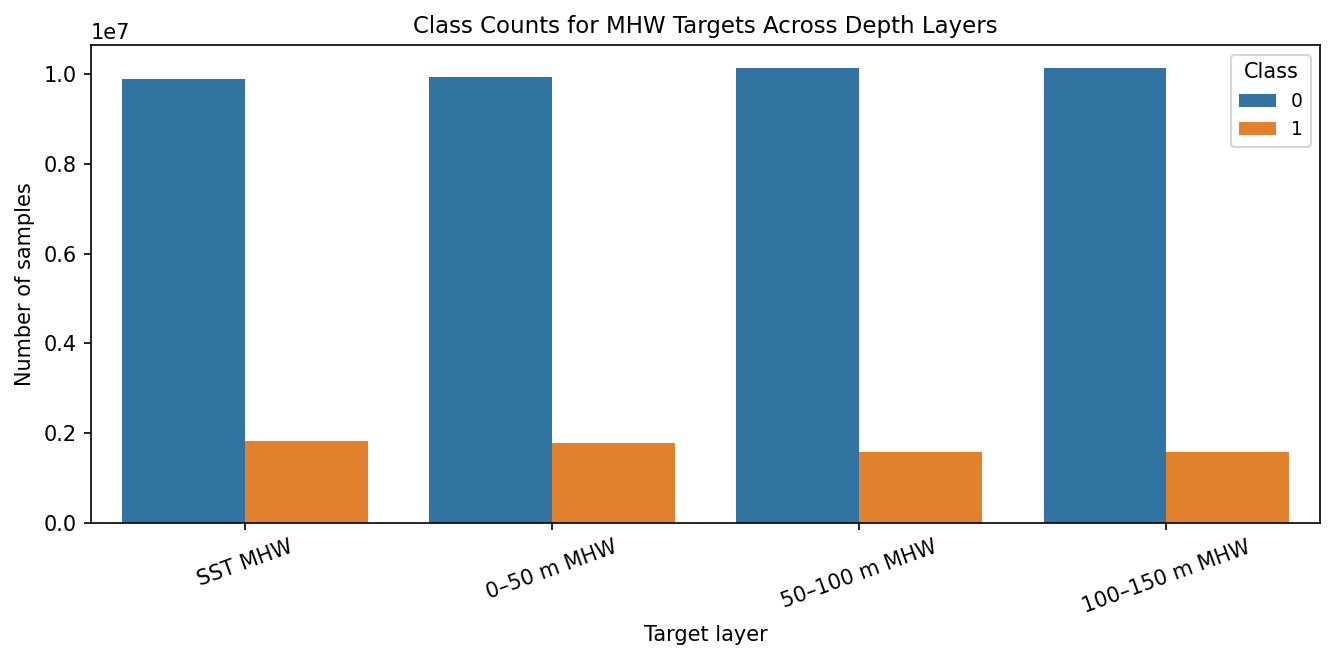

,Layer,Class,Count
0,SST MHW,0,9893677
1,SST MHW,1,1809786
2,0–50 m MHW,0,9931173
3,0–50 m MHW,1,1772290
4,50–100 m MHW,0,10126688
5,50–100 m MHW,1,1576775
6,100–150 m MHW,0,10132295
7,100–150 m MHW,1,1571168


In [ ]:
plot_class_counts_all_layers(df)

# View Nan Values in a Map in Each Feature

In [ ]:
def plot_nan_maps_features(df, columns):
    n = len(columns)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 12))
    axes = axes.flatten()

    for i, col in enumerate(columns):
        ax = axes[i]

        valid_df = df[df[col].notna()]
        nan_df = df[df[col].isna()]

        ax.scatter(valid_df['longitude'], valid_df['latitude'],
                   s=2, color='green', alpha=0.25, label='Valid')

        ax.scatter(nan_df['longitude'], nan_df['latitude'],
                   s=6, color='red', alpha=0.8, label='NaN')

        ax.set_title(col)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.grid(True)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right')

    plt.suptitle('Valid and Missing Data Locations Across All Features', fontsize=14)
    plt.tight_layout()
    plt.show()



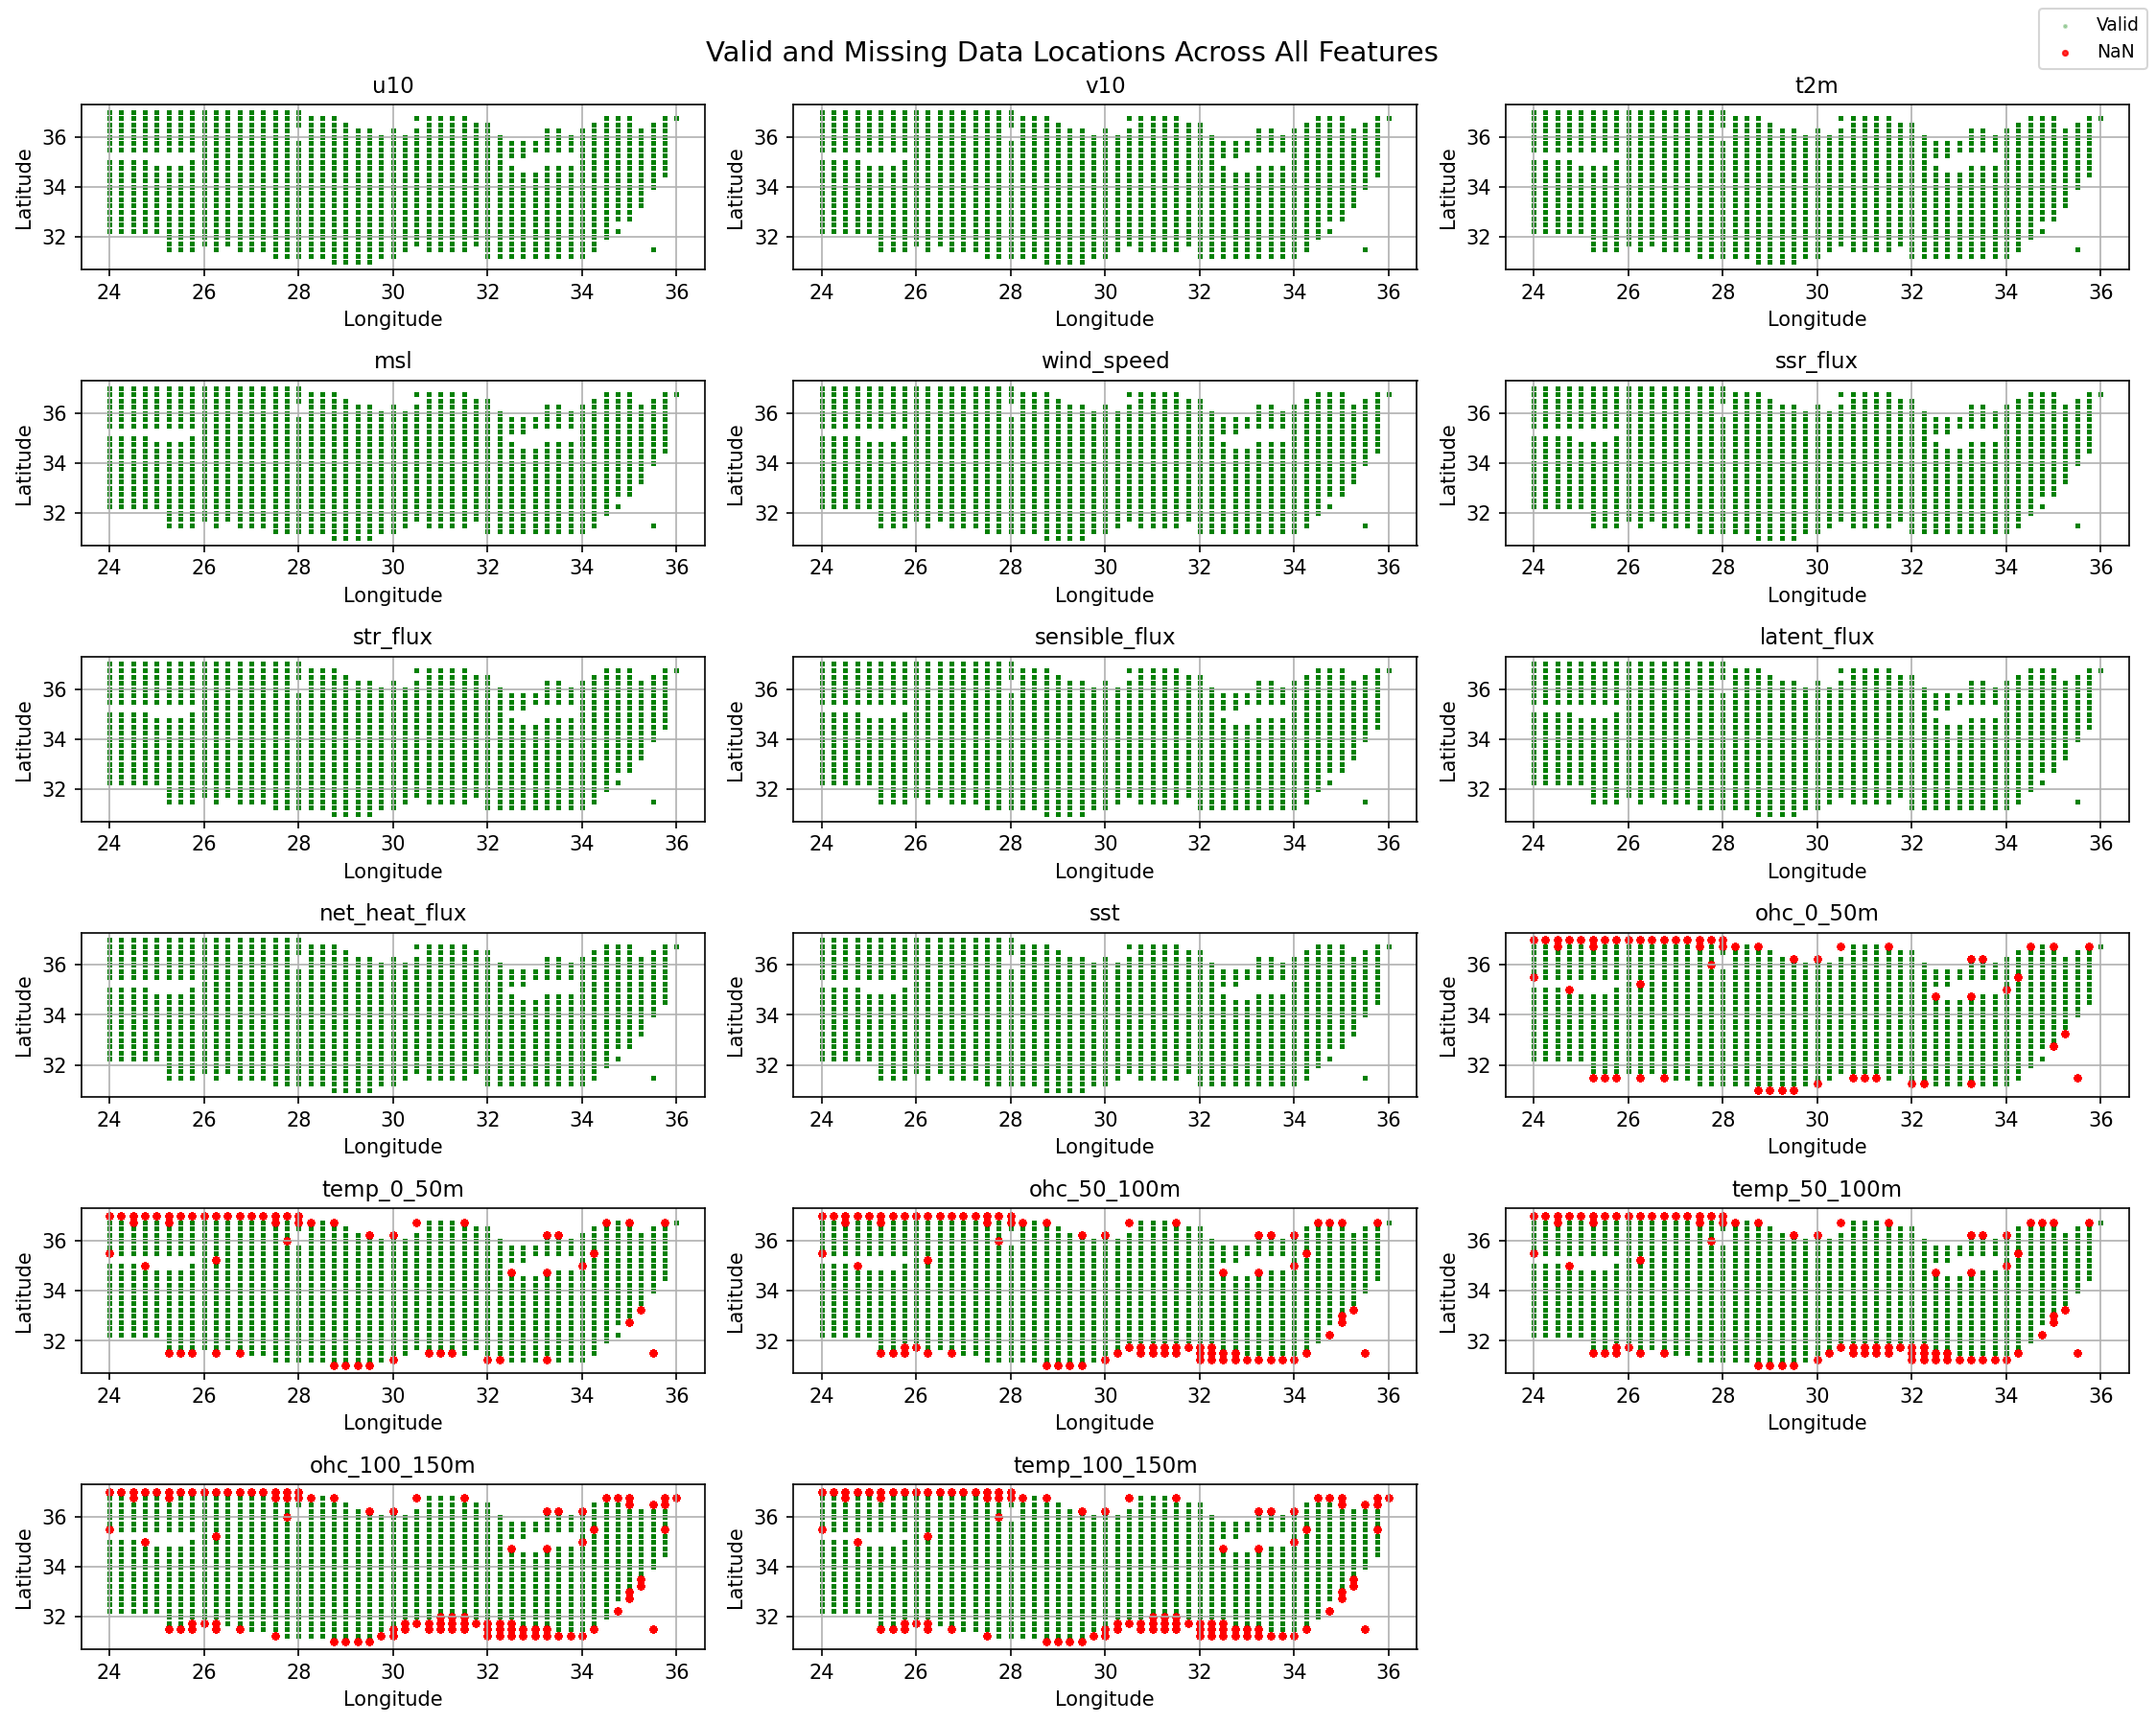

In [ ]:
plot_nan_maps_features(df, ALL_FEATURES)

In [ ]:

(
df[ALL_FEATURES].isna().sum() / len(df)
) * 100



,0
u10,0.000000
v10,0.000000
t2m,0.000000
msl,0.000000
wind_speed,0.000000
ssr_flux,0.000000
str_flux,0.000000
sensible_flux,0.000000
latent_flux,0.000000
net_heat_flux,0.000000


In [ ]:
total_cells = df.shape[0] * df.shape[1]
total_nas = df.isna().sum().sum()

overall_na_rate = (total_nas / total_cells) * 100

print(f'Total NA values: {total_nas:,}')
print(f'Overall NA rate: {overall_na_rate:.2f}%')

Total NA values: 6,002,394
Overall NA rate: 1.90%


# Check for Missing Dates

In [ ]:
# Check missing dates
expected_dates = pd.date_range(df['time'].min(), df['time'].max(), freq='D')
actual_dates = pd.DatetimeIndex(df['time'].drop_duplicates().sort_values())
missing_dates = expected_dates.difference(actual_dates)

print('Expected days:', len(expected_dates))
print('Actual days:', len(actual_dates))
print('Missing days:', len(missing_dates))
print(missing_dates[:10])

Expected days: 12053
Actual days: 12053
Missing days: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


# Check Temporal Continuity

In [ ]:
fig, axes = plt.subplots(len(ALL_FEATURES), 1, figsize=(28, 25), sharex=True)

for ax, feature in zip(axes, ALL_FEATURES):
    for _, group in df.groupby(['latitude', 'longitude']):
        group = group.sort_values('time')
        ax.plot(group['time'], group[feature], alpha=0.05, linewidth=0.5)

    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Time')
plt.suptitle('Temporal Continuity Across All Lat-Long Grid Points', fontweight='bold')
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# Outlier Check of All Features

In [ ]:
def plot_raw_boxplots_all_features(df):
    n = len(ALL_FEATURES)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4*nrows))
    axes = axes.flatten()

    for ax, feature in zip(axes, ALL_FEATURES):
        sns.boxplot(x=df[feature].dropna(), ax=ax)
        ax.set_title(feature)
        ax.set_xlabel('Raw value')
        ax.grid(True, alpha=0.3)

    for ax in axes[len(ALL_FEATURES):]:
        ax.axis('off')

    plt.suptitle('Outlier Check - All Features', fontweight='bold')
    plt.tight_layout()
    savefig('outliers_all_features_original_scales')
    plt.show()

  Saved --> /content/drive/MyDrive/MSc-research-code/EDA/outliers_all_features_original_scales.png


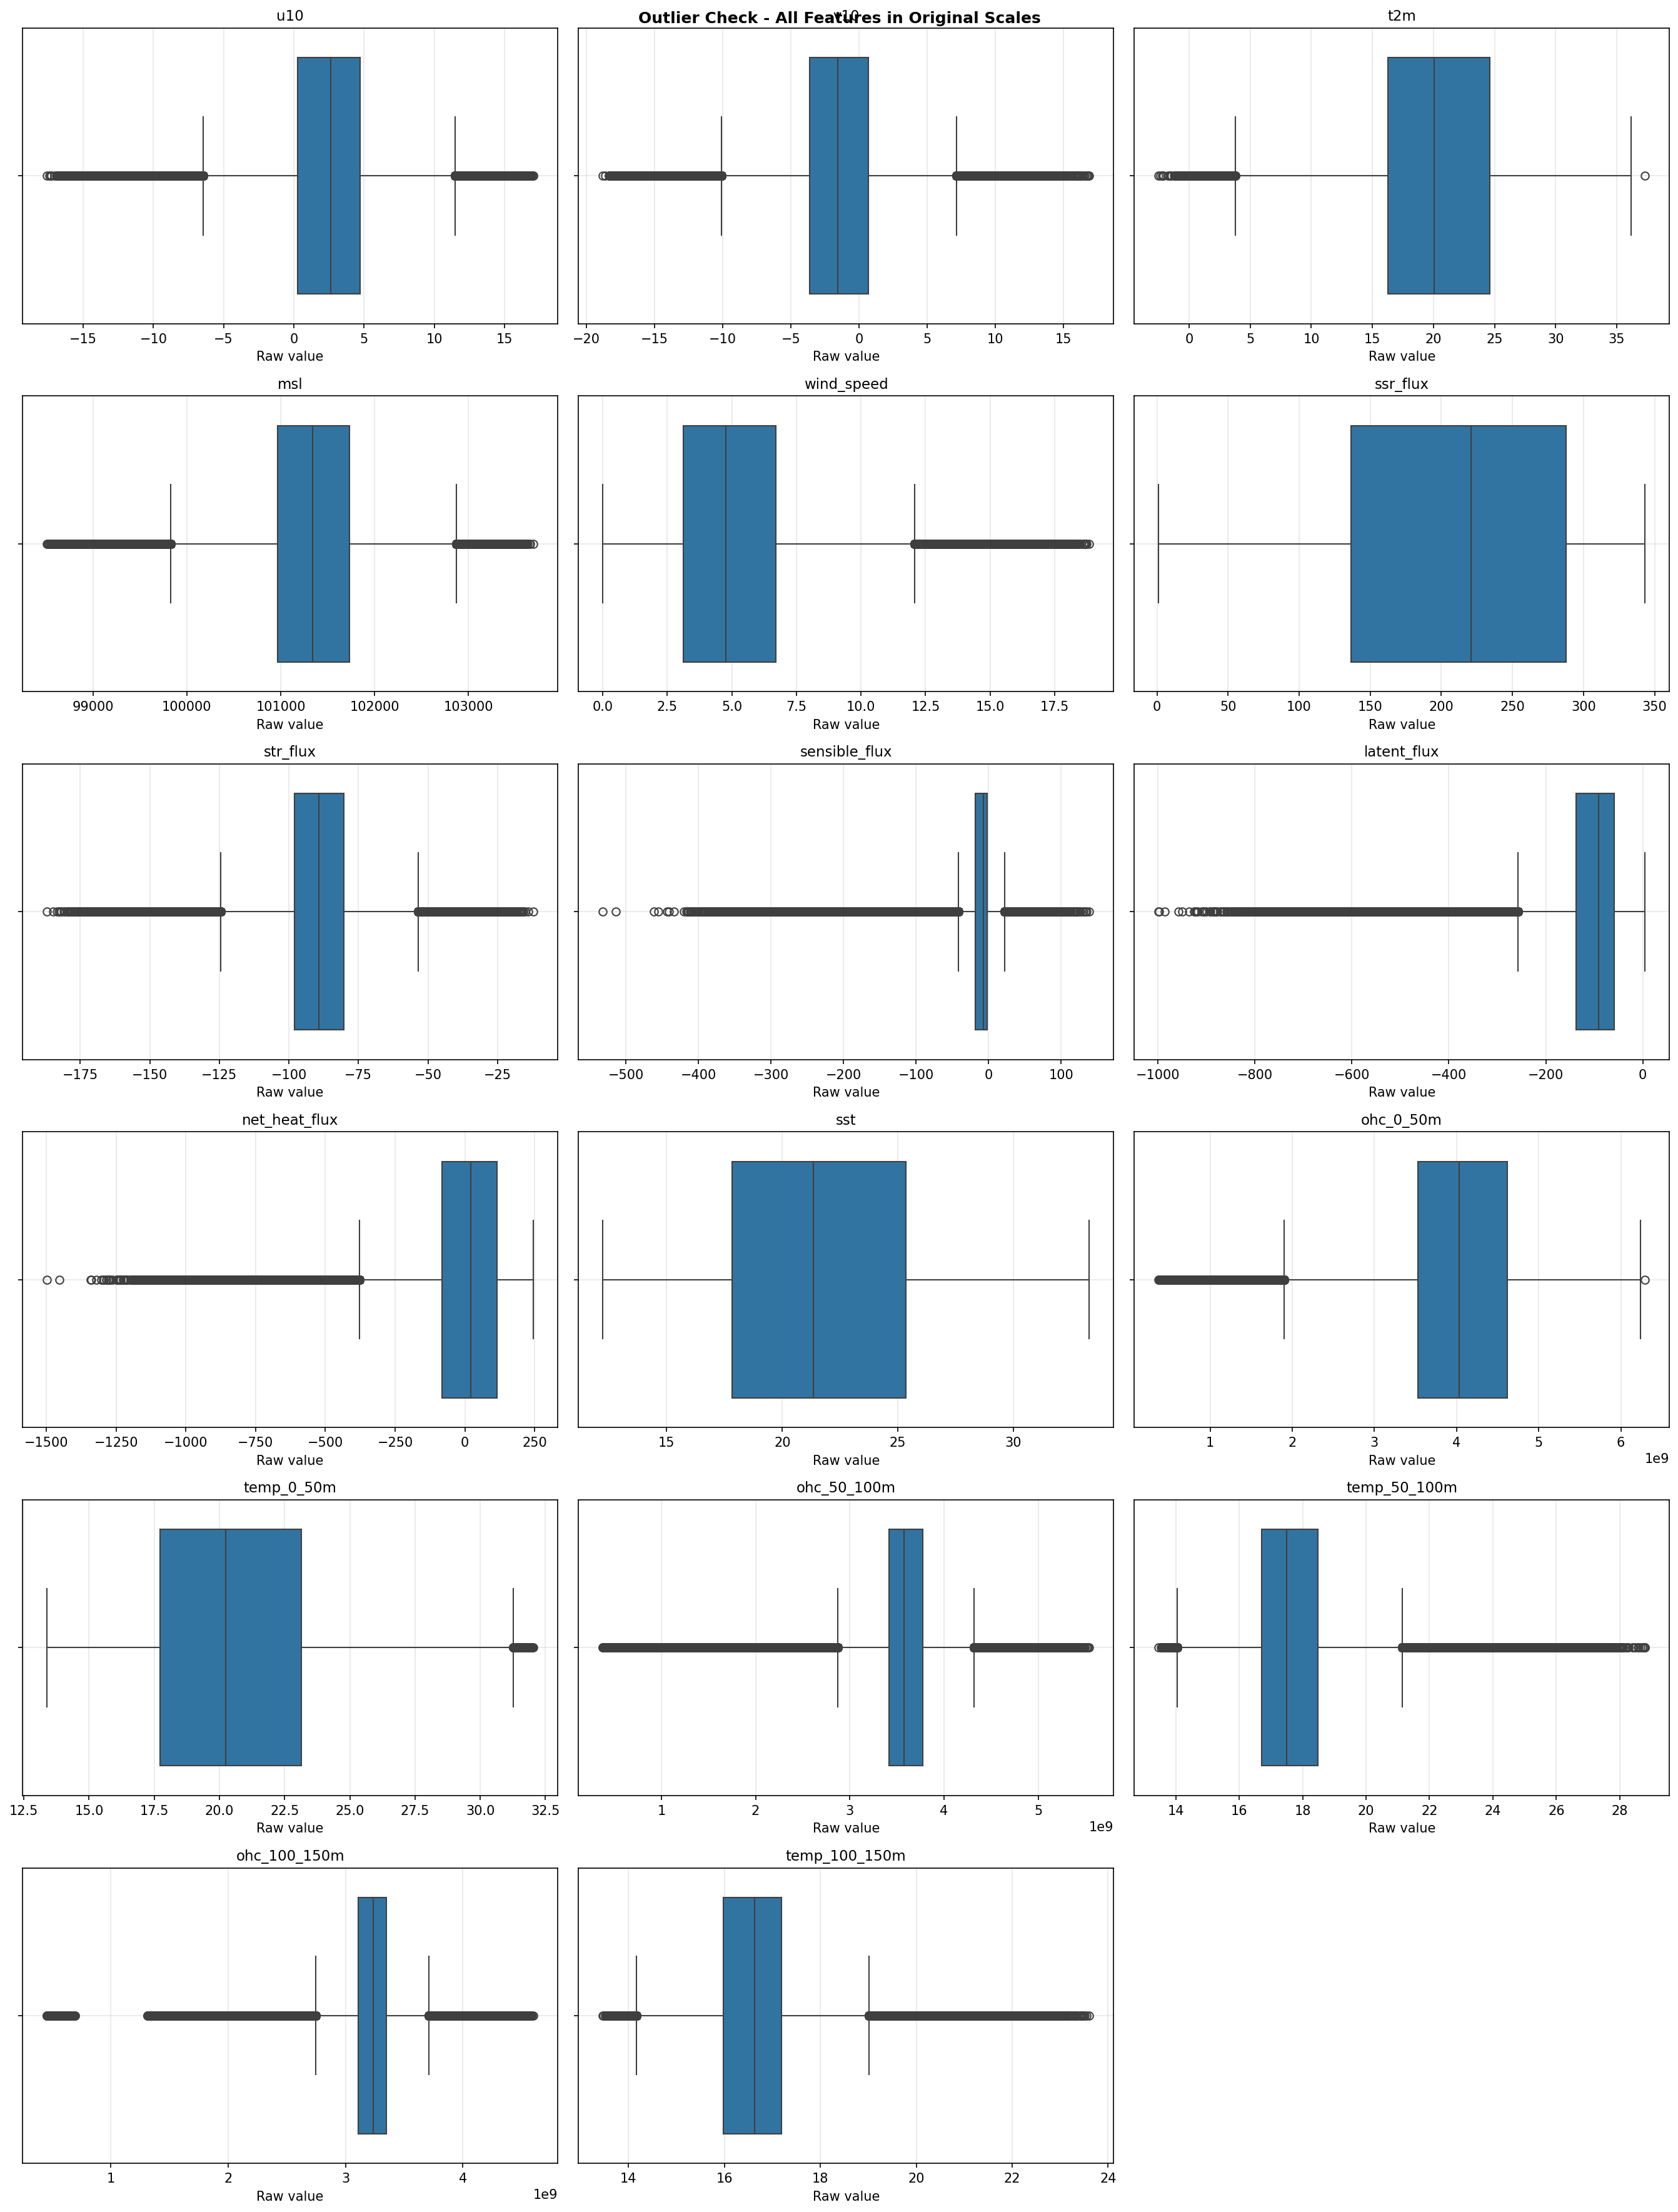

In [ ]:
plot_raw_boxplots_all_features(df)

In [ ]:

df[ALL_FEATURES].describe().T


,count,mean,std,min,25%,50%,75%,max
u10,11703463.0,2.388836e+00,3.506361e+00,-1.756723e+01,2.540207e-01,2.606232e+00,4.739248e+00,1.704678e+01
v10,11703463.0,-1.451477e+00,3.519670e+00,-1.878806e+01,-3.629814e+00,-1.546600e+00,6.800041e-01,1.688879e+01
t2m,11703463.0,2.024500e+01,4.690263e+00,-2.492737e+00,1.627139e+01,2.004794e+01,2.460721e+01,3.731351e+01
msl,11703463.0,1.013666e+05,1.472789e+04,9.851123e+04,1.009701e+05,1.013374e+05,1.017303e+05,1.036913e+05
wind_speed,11703463.0,5.086430e+00,2.646392e+00,1.862393e-03,3.116423e+00,4.773712e+00,6.703336e+00,1.883709e+01
ssr_flux,11703463.0,2.115347e+02,7.974480e+01,1.195312e+00,1.362891e+02,2.209102e+02,2.879336e+02,3.432188e+02
str_flux,11703463.0,-8.902702e+01,1.436874e+01,-1.869422e+02,-9.791175e+01,-8.917209e+01,-8.015332e+01,-1.212203e+01
sensible_flux,11703463.0,-1.352146e+01,2.190469e+01,-5.319596e+02,-1.805194e+01,-7.353577e+00,-2.000854e+00,1.384802e+02
latent_flux,11703463.0,-1.082418e+02,7.218288e+01,-9.986765e+02,-1.377204e+02,-9.040082e+01,-5.820392e+01,4.572021e+00
net_heat_flux,11703463.0,7.444450e-01,1.423969e+02,-1.497268e+03,-8.243975e+01,2.087970e+01,1.150233e+02,2.452708e+02


# Correlation Map Check

In [ ]:
def plot_correlation_heatmap(df):

    corr = df[ALL_FEATURES+TARGETS].corr()

    plt.figure(figsize=(28, 16))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
    plt.title('Correlation Matrix of Atmospheric and Ocean Temperature Features')
    savefig('feature_correlation_heatmap')



  Saved --> /content/drive/MyDrive/MSc-research-code/EDA/feature_correlation_heatmap.png


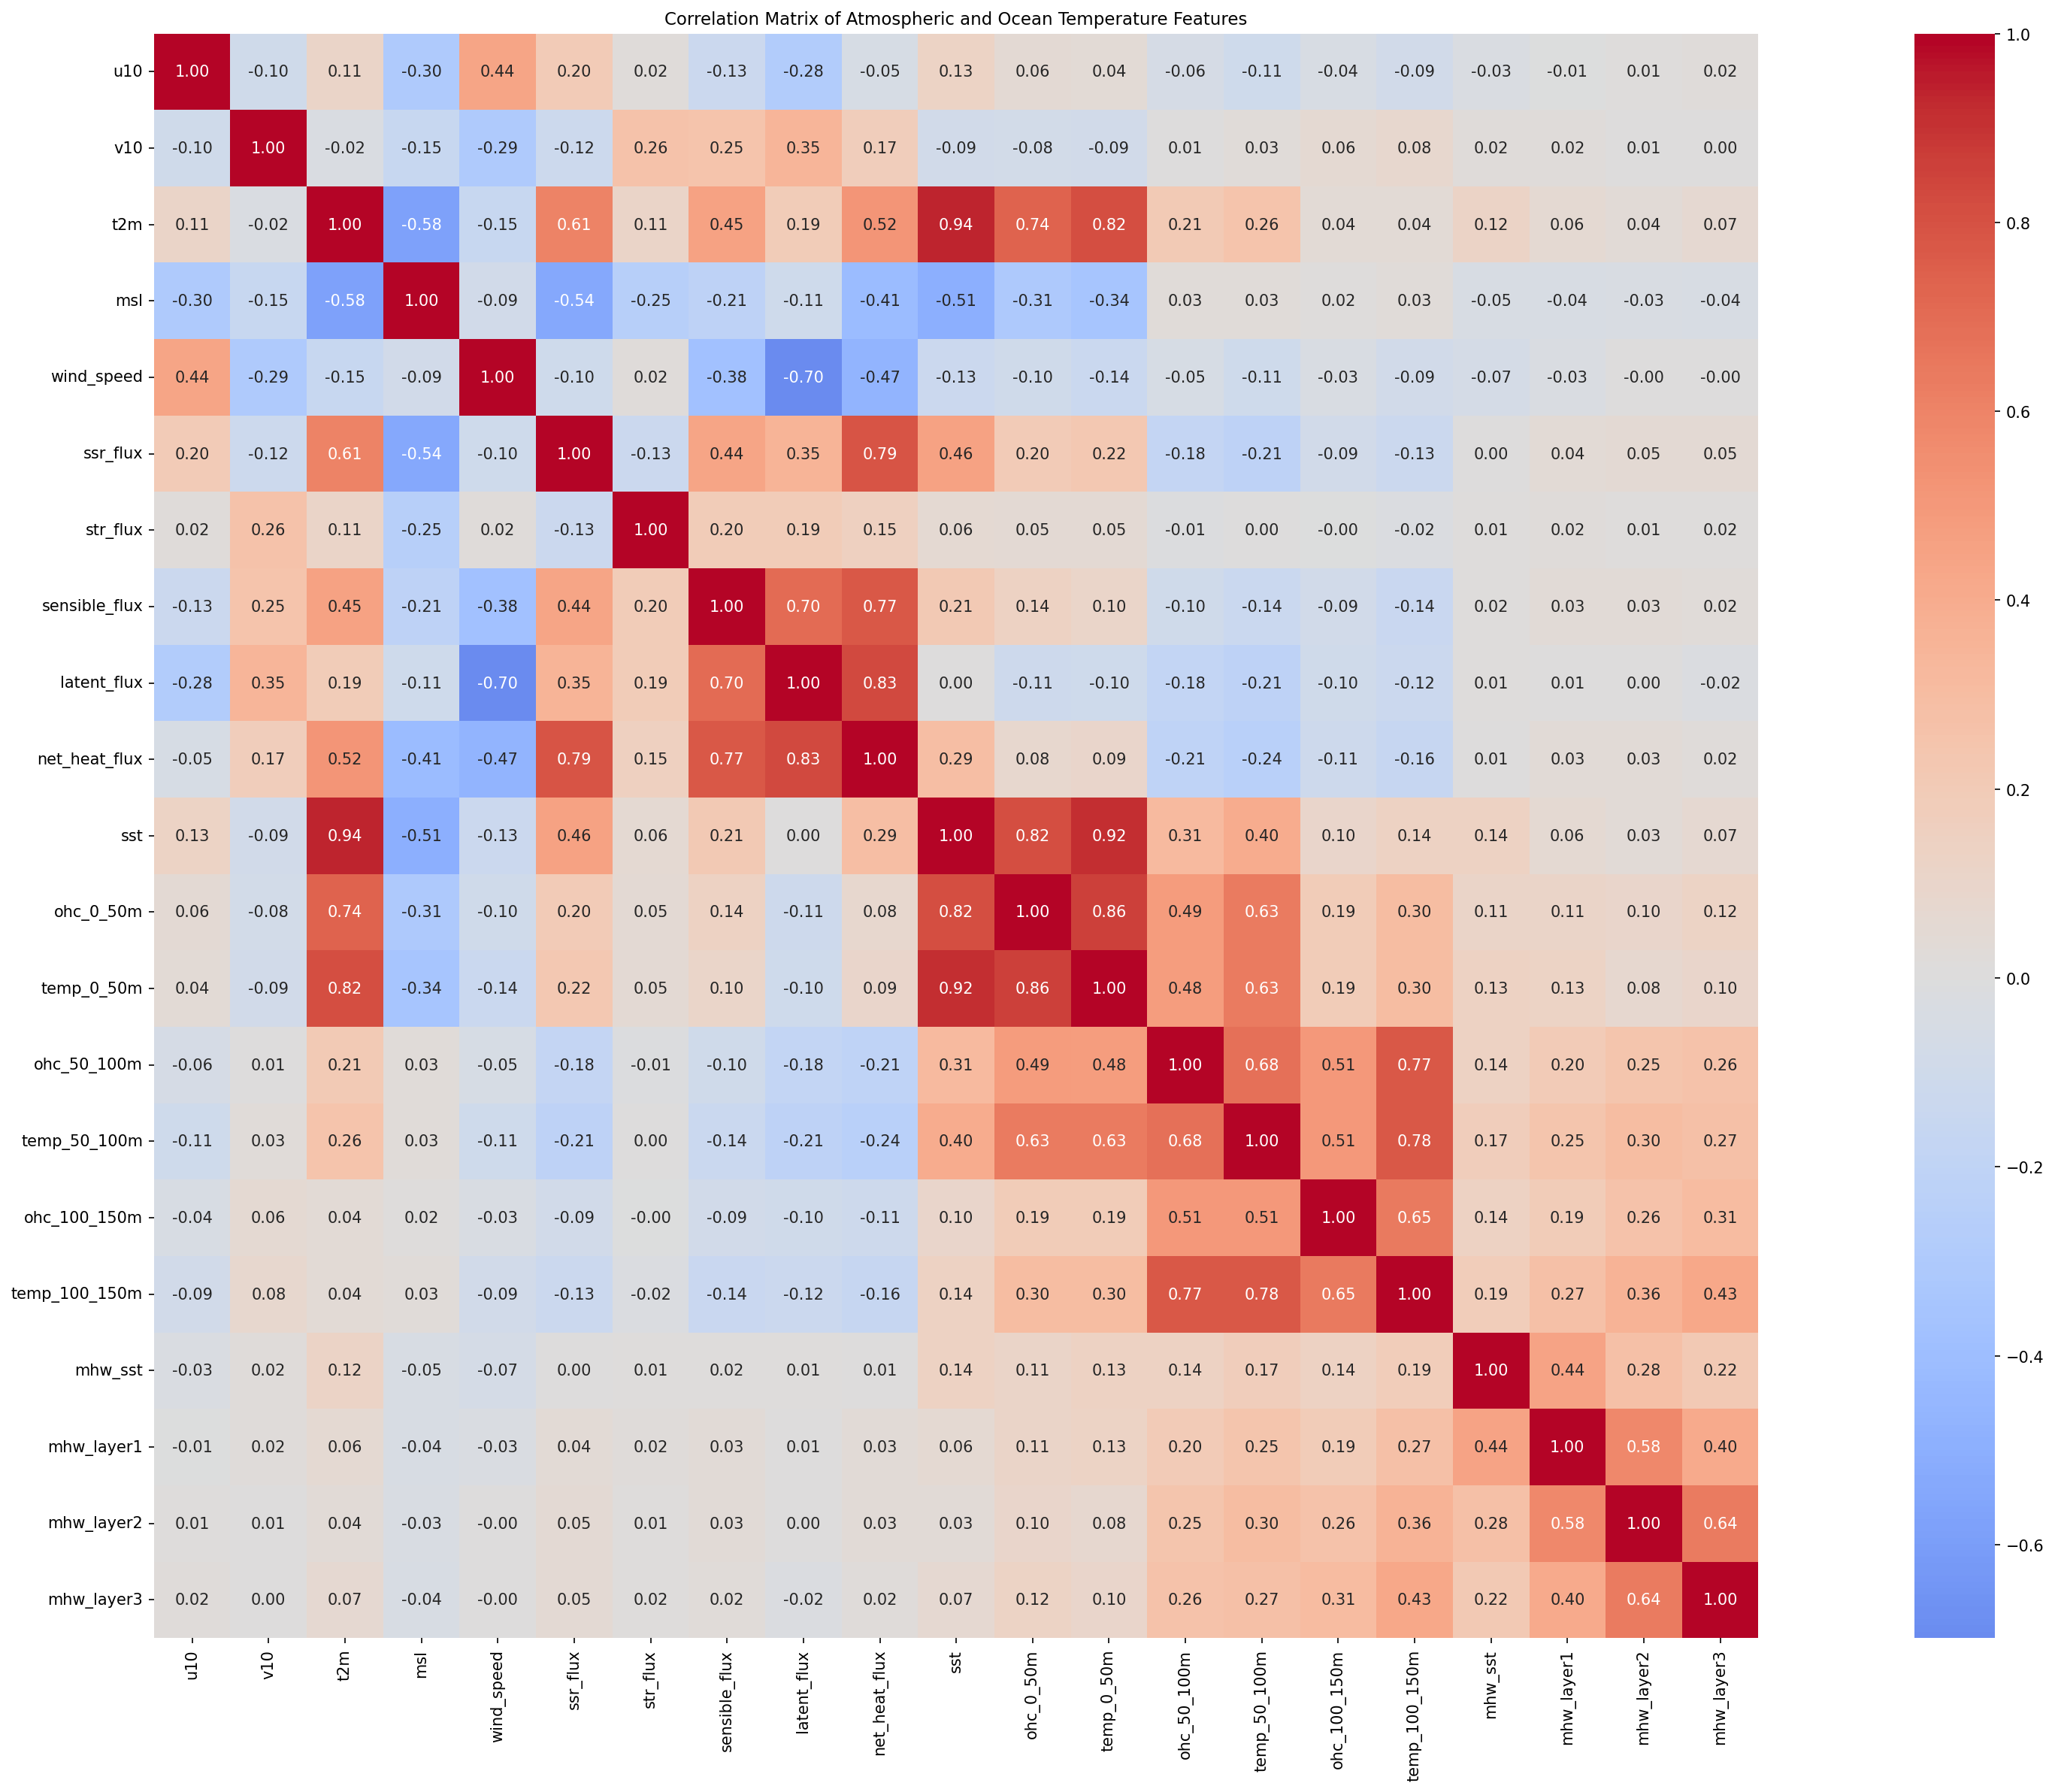

In [ ]:
plot_correlation_heatmap(df)

# Surface and Subsurface Coupling

In [ ]:
def surface_subsurface_coupling(df):
    rows = []

    sst_mhw = df['mhw_sst'] == 1
    total_sst_mhw = sst_mhw.sum()

    for target, name in zip(TARGETS[1:], TARGET_NAMES[1:]):
        concurrent = sst_mhw & (df[target] == 1)
        coupling = (concurrent.sum() / total_sst_mhw) * 100

        rows.append({
            'Layer': name,
            'SST co-occurrence (%)': round(coupling, 2)
        })

    return pd.DataFrame(rows)


In [ ]:
surface_subsurface_coupling(df)

,Layer,SST co-occurrence (%)
0,0–50 m MHW,52.33
1,50–100 m MHW,35.73
2,100–150 m MHW,30.68


In [12]:
TRAIN_END_DATE = '2019-12-31'
VAL_START_DATE = '2020-01-15'
VAL_END_DATE = '2022-12-31'
TEST_START_DATE = '2023-01-15'

df['time'] = pd.to_datetime(df['time'])
train_df = df[df['time'] <= TRAIN_END_DATE].copy()
val_df = df[(df['time'] >= VAL_START_DATE) & (df['time'] <= VAL_END_DATE)].copy()
test_df = df[df['time'] >= TEST_START_DATE].copy()

print(f'Train: {len(train_df):,} samples')
print(f'Validation: {len(val_df):,} samples')
print(f'Test:  {len(test_df):,} samples')

Train: 9,575,031 samples
Validation: 1,050,622 samples
Test:  1,050,622 samples


# Distribution Shift Check

In [ ]:
def plot_distribution_shift_all_layers(df_train, df_val, df_test):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
    axes = axes.ravel()

    for ax, var, name in zip(axes, LAYER_FEATURES, LAYER_NAMES):
        sns.kdeplot(df_train[var].dropna(), ax=ax, label='Train')
        sns.kdeplot(df_val[var].dropna(), ax=ax, label='Validation')
        sns.kdeplot(df_test[var].dropna(), ax=ax, label='Test')
        ax.set_title(name)
        ax.set_xlabel('Temperature (°C)')
        ax.set_ylabel('Density')
        ax.legend()

    fig.suptitle('Distribution Shift Across Data Splits and Depth Layers', fontsize=14)
    savefig('distribution_shift_all_layers')

  Saved --> /content/drive/MyDrive/MSc-research-code/EDA/distribution_shift_all_layers.png


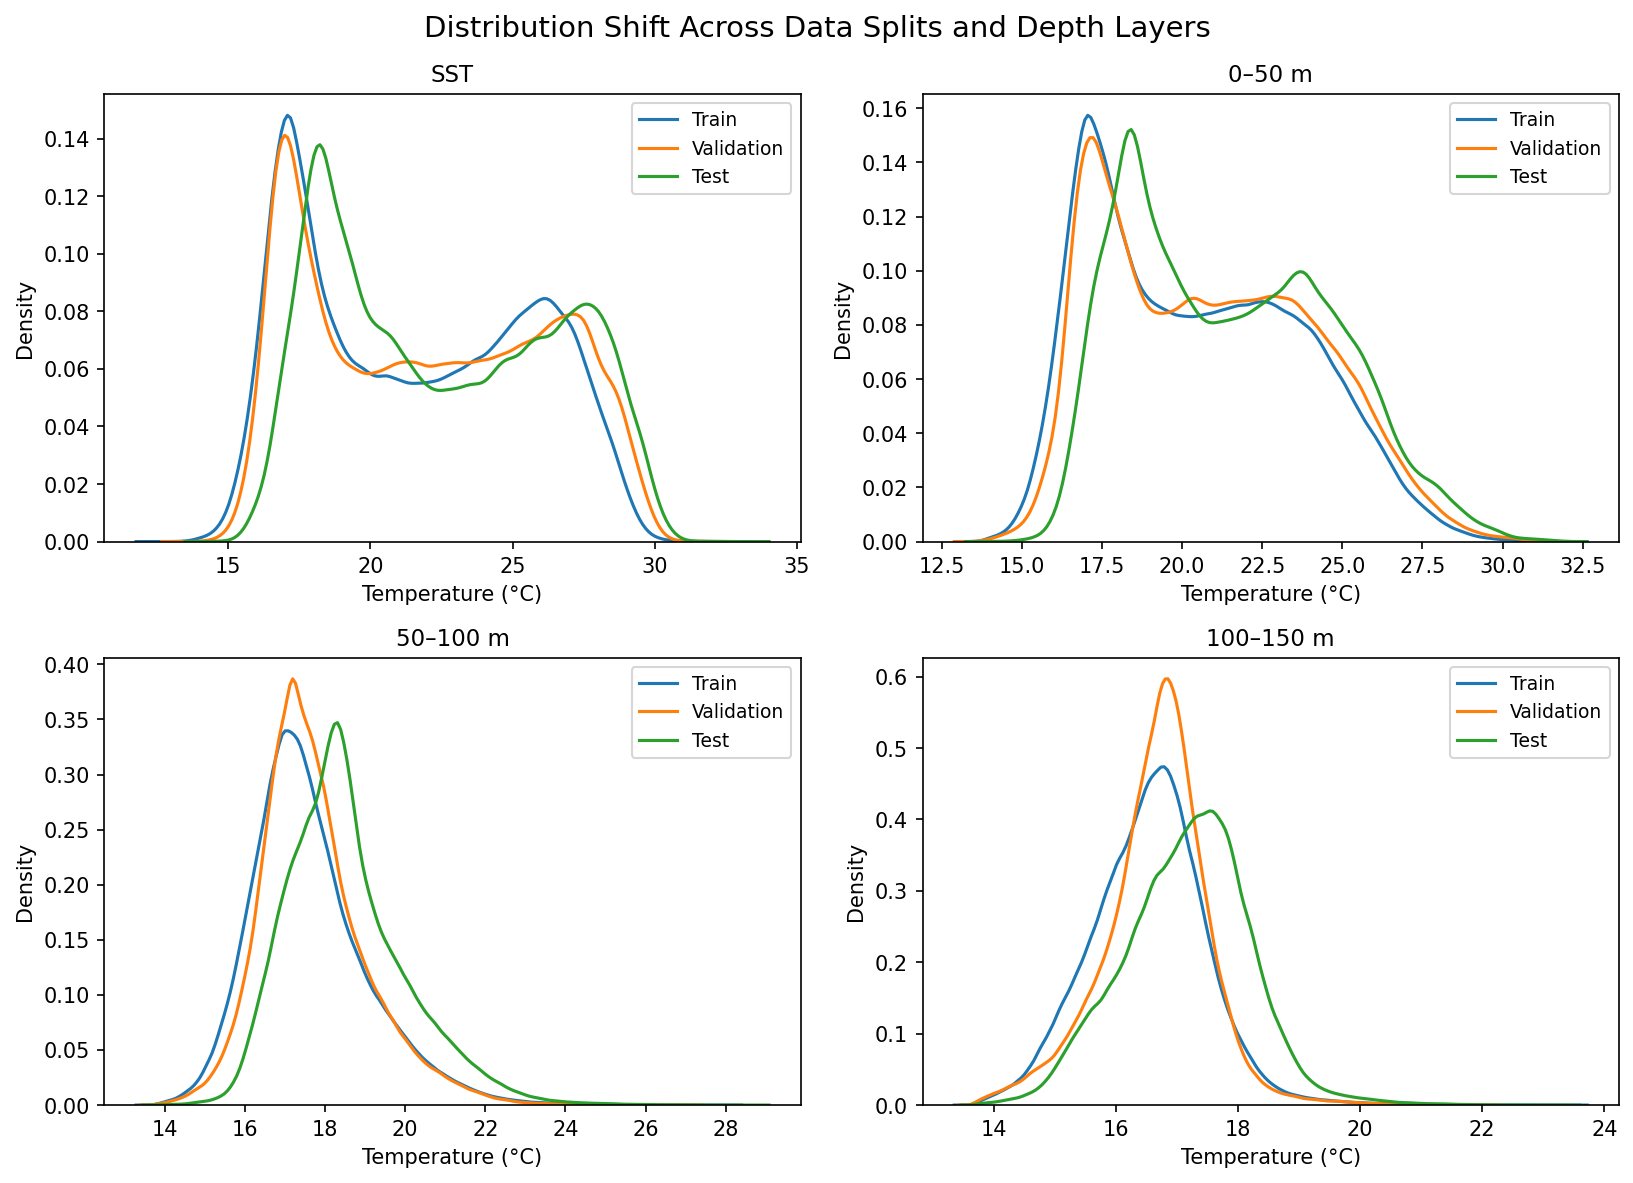

In [ ]:
plot_distribution_shift_all_layers(train_df, val_df, test_df)

In [ ]:
def plot_mhw_rate_shift_all_layers(df_train, df_val, df_test):
    rows = []

    for target, name in zip(TARGETS, TARGET_NAMES):
        rows.append({
            'Layer': name,
            'Split': 'Train',
            'MHW Rate (%)': df_train[target].mean() * 100
        })
        rows.append({
            'Layer': name,
            'Split': 'Validation',
            'MHW Rate (%)': df_val[target].mean() * 100
        })
        rows.append({
            'Layer': name,
            'Split': 'Test',
            'MHW Rate (%)': df_test[target].mean() * 100
        })

    out = pd.DataFrame(rows)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=out,
        x='Layer',
        y='MHW Rate (%)',
        hue='Split'
    )

    plt.title('MHW Rate Distribution Shift Across Train, Validation, and Test Sets')
    plt.xlabel('Depth Layer')
    plt.ylabel('MHW Rate (%)')
    plt.xticks(rotation=20)
    plt.legend(title='Data Split')
    plt.tight_layout()

    savefig('mhw_rate_distribution_shift_train_val_test')
    plt.show()

    return out

  Saved --> /content/drive/MyDrive/MSc-research-code/EDA/mhw_rate_distribution_shift_train_val_test.png


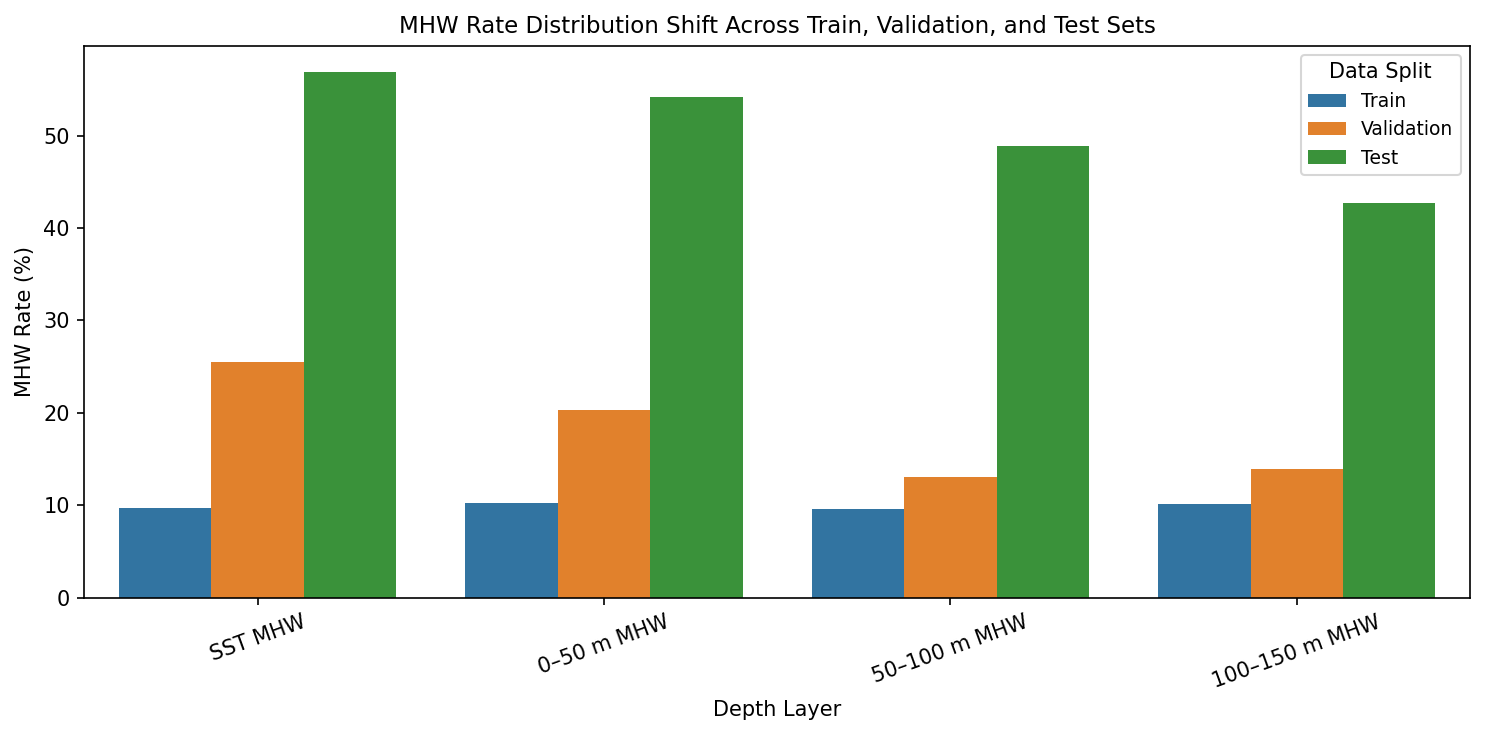

,Layer,Split,MHW Rate (%)
0,SST MHW,Train,9.725493
1,SST MHW,Validation,25.483095
2,SST MHW,Test,56.908384
3,0–50 m MHW,Train,10.235925
4,0–50 m MHW,Validation,20.344234
5,0–50 m MHW,Test,54.213599
6,50–100 m MHW,Train,9.631447
7,50–100 m MHW,Validation,12.998681
8,50–100 m MHW,Test,48.926160
9,100–150 m MHW,Train,10.181158


In [ ]:
plot_mhw_rate_shift_all_layers(train_df, val_df, test_df)


In [ ]:

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values(
    ["latitude", "longitude", "time"]
).copy()

target_cols = {
    "SST": "mhw_sst",
    "0–50 m": "mhw_layer1",
    "50–100 m": "mhw_layer2",
    "100–150 m": "mhw_layer3",
}

def count_mhw_events(data, target_col):
    total_events = 0

    for _, cell in data.groupby(["latitude", "longitude"]):
        cell = cell.sort_values("time").copy()

        # New run if there is a date gap
        new_run = cell["time"].diff().dt.days.ne(1)
        new_run.iloc[0] = True

        # New run when the label changes
        label_change = cell[target_col].ne(
            cell[target_col].shift()
        )

        cell["run_id"] = (
            new_run | label_change
        ).cumsum()

        runs = cell.groupby("run_id").agg(
            label=(target_col, "first"),
            days=(target_col, "size")
        )

        total_events += int(
            (
                (runs["label"] == 1) &
                (runs["days"] >= 5)
            ).sum()
        )

    return total_events


results = []

for layer, target_col in target_cols.items():
    event_count = count_mhw_events(df, target_col)

    results.append({
        "Depth layer": layer,
        "MHW event count": event_count
    })

event_counts_df = pd.DataFrame(results)
print(event_counts_df.to_string(index=False))


Depth layer  MHW event count
        SST           107656
     0–50 m            90025
   50–100 m            74028
  100–150 m            67898


In [ ]:
for col in [
    "mhw_sst",
    "mhw_layer1",
    "mhw_layer2",
    "mhw_layer3"
]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


mhw_sst
mhw_sst
0    9893677
1    1809786
Name: count, dtype: int64

mhw_layer1
mhw_layer1
0    9931173
1    1772290
Name: count, dtype: int64

mhw_layer2
mhw_layer2
0    10126688
1     1576775
Name: count, dtype: int64

mhw_layer3
mhw_layer3
0    10132295
1     1571168
Name: count, dtype: int64


In [ ]:
# Check duplicate dates within each grid cell
duplicates = df.duplicated(
    subset=["latitude", "longitude", "time"]
).sum()

print("Duplicate grid-cell dates:", duplicates)

# Check the number of unique grid cells
print(
    "Unique grid cells:",
    df[["latitude", "longitude"]].drop_duplicates().shape[0]
)

Duplicate grid-cell dates: 0
Unique grid cells: 971


In [ ]:

cell = (
    df[
        (df["latitude"] == df["latitude"].iloc[0]) &
        (df["longitude"] == df["longitude"].iloc[0])
    ]
    .sort_values("time")
    .copy()
)

cell["new_run"] = (
    cell["time"].diff().dt.days.ne(1) |
    cell["mhw_sst"].ne(cell["mhw_sst"].shift())
)

cell["run_id"] = cell["new_run"].cumsum()

runs = cell.groupby("run_id").agg(
    start_date=("time", "min"),
    end_date=("time", "max"),
    label=("mhw_sst", "first"),
    records=("mhw_sst", "size")
)

print(runs[runs["label"] == 1].head(10))


       start_date   end_date  label  records
run_id                                      
2      1995-03-14 1995-03-21      1        8
4      1997-01-02 1997-01-07      1        6
6      1998-02-05 1998-02-09      1        5
8      1999-04-28 1999-05-11      1       14
10     2001-03-23 2001-04-18      1       27
12     2002-07-13 2002-07-21      1        9
14     2002-10-02 2002-10-07      1        6
16     2003-02-02 2003-02-08      1        7
18     2003-05-19 2003-05-24      1        6
20     2003-06-17 2003-06-21      1        5


In [ ]:

target_cols = {
    "SST": "mhw_sst",
    "0–50 m": "mhw_layer1",
    "50–100 m": "mhw_layer2",
    "100–150 m": "mhw_layer3",
}

for layer, col in target_cols.items():
    short_runs = 0
    positive_runs = 0

    for _, cell in df.groupby(["latitude", "longitude"]):
        cell = cell.sort_values("time").copy()

        new_run = (
            cell["time"].diff().dt.days.ne(1)
            | cell[col].ne(cell[col].shift())
        )

        cell["run_id"] = new_run.cumsum()

        runs = cell.groupby("run_id").agg(
            label=(col, "first"),
            records=(col, "size")
        )

        positive = runs[runs["label"] == 1]
        positive_runs += len(positive)
        short_runs += int((positive["records"] < 5).sum())

    print(
        f"{layer}: positive runs={positive_runs:,}, "
        f"runs shorter than 5 days={short_runs:,}"
    )


SST: positive runs=107,656, runs shorter than 5 days=0
0–50 m: positive runs=90,025, runs shorter than 5 days=0
50–100 m: positive runs=74,028, runs shorter than 5 days=0
100–150 m: positive runs=67,898, runs shorter than 5 days=0


# Study Area Map (Paper Figure)
The 971 grid cells of the Levantine Basin study region (31–37°N, 24–36°E), coloured by the deepest layer with valid data.

Grid cells: 971
deepest
to 150 m        867
surface only     59
to 50 m          27
to 100 m         18


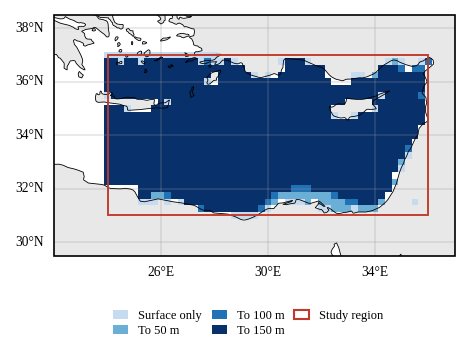

Saved: /content/drive/MyDrive/MSc-research-code/EDA/study_area.pdf and study_area.png


In [13]:
#Deepest valid layer per grid cell (valid = data on more than half of the days)
LAYER_COLS = ['sst', 'temp_0_50m', 'temp_50_100m', 'temp_100_150m']
valid_frac = df.groupby(['latitude', 'longitude'])[LAYER_COLS].agg(lambda s: s.notna().mean())
valid      = valid_frac > 0.5
deepest    = valid.astype(int).sum(axis=1)          # 1 = surface only ... 4 = to 150 m
cells      = deepest.reset_index(name='deepest')

print(f'Grid cells: {len(cells)}')
print(cells['deepest'].map({1: 'surface only', 2: 'to 50 m', 3: 'to 100 m',
                            4: 'to 150 m'}).value_counts().to_string())

# Regular grid for pcolormesh
lats = np.sort(cells['latitude'].unique())
lons = np.sort(cells['longitude'].unique())
grid = np.full((len(lats), len(lons)), np.nan)
iy   = np.searchsorted(lats, cells['latitude'].values)
ix   = np.searchsorted(lons, cells['longitude'].values)
grid[iy, ix] = cells['deepest'].values
dlat = np.median(np.diff(lats)); dlon = np.median(np.diff(lons))
lat_e = np.r_[lats - dlat / 2, lats[-1] + dlat / 2]
lon_e = np.r_[lons - dlon / 2, lons[-1] + dlon / 2]

colours = ['#c6dbef', '#6baed6', '#2171b5', '#08306b']
labels  = ['Surface only', 'To 50 m', 'To 100 m', 'To 150 m']
cmap    = ListedColormap(colours)
norm    = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap.N)

paper_rc = {'pdf.fonttype': 42, 'font.family': 'serif',
            'font.serif': ['Liberation Serif', 'TeX Gyre Termes', 'Nimbus Roman',
                           'Times New Roman', 'DejaVu Serif'],
            'mathtext.fontset': 'stix', 'font.size': 7}

EXTENT = [22, 37, 29.5, 38.5]      # lon_min, lon_max, lat_min, lat_max (map frame)
BOX    = [24, 36, 31, 37]          # study region from the paper

with mpl.rc_context(paper_rc):
    if HAS_CARTOPY:
        proj = ccrs.PlateCarree()
        fig  = plt.figure(figsize=(3.45, 2.2))
        ax   = fig.add_subplot(1, 1, 1, projection=proj)
        ax.set_extent(EXTENT, crs=proj)
        ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#e8e8e8', zorder=0)
        ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.4, zorder=3)
        ax.pcolormesh(lon_e, lat_e, grid, cmap=cmap, norm=norm,
                      transform=proj, zorder=1)
        ax.add_patch(Rectangle((BOX[0], BOX[2]), BOX[1] - BOX[0], BOX[3] - BOX[2],
                               fill=False, ec='#c0392b', lw=0.9, transform=proj, zorder=4))
        gl = ax.gridlines(draw_labels=True, linewidth=0.2, color='#999',
                          xlocs=range(22, 38, 4), ylocs=range(30, 39, 2))
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {'size': 6.5}
    else:
        fig, ax = plt.subplots(figsize=(3.45, 2.2))
        ax.set_facecolor('#e8e8e8')                  # land / no data
        ax.pcolormesh(lon_e, lat_e, grid, cmap=cmap, norm=norm)
        ax.add_patch(Rectangle((BOX[0], BOX[2]), BOX[1] - BOX[0], BOX[3] - BOX[2],
                               fill=False, ec='#c0392b', lw=0.9))
        ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
        ax.set_aspect(1 / np.cos(np.deg2rad(34)))
        ax.set_xlabel('Longitude (°E)', fontsize=6.5)
        ax.set_ylabel('Latitude (°N)', fontsize=6.5)
        ax.tick_params(labelsize=6.5)

    handles = [Patch(facecolor=c, edgecolor='none', label=l) for c, l in zip(colours, labels)]
    handles.append(Patch(facecolor='none', edgecolor='#c0392b', label='Study region'))
    # legend below the map so it does not hide any grid cells
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0),
              ncol=3, fontsize=6, frameon=False, handlelength=1.2,
              columnspacing=0.8, labelspacing=0.25)

    fig.savefig(FIG_DIR / 'study_area.pdf', bbox_inches='tight', pad_inches=0.02)
    fig.savefig(FIG_DIR / 'study_area.png', dpi=300, bbox_inches='tight')
    plt.show()

print(f"Saved: {FIG_DIR / 'study_area.pdf'} and study_area.png")